
# CI7340 CW1 — Dataset Understanding and Data Quality Assessment

**Group 8 | Applied Data Programming | Research Report and Visualisation**

**Team Members:**

    Aruna D Mahagamage (K2600143)
    Baba Isham Sally (K2703532)
    K G Nilanga Nayanajith Abeysekara (K2703512)
    Mihiri Thilakaratne (K2703522)

**Scope:** This notebook covers dataset understanding, the essential CW1 data-quality checks, and one shared analytical dataset. Research questions are completed separately.



## 1. Environment Setup

### 1.1 Install Required Libraries

**Aim:** Install the Python libraries required for data analysis, data cleaning, visualisation and statistical testing.

**Libraries:**
- `pandas` - Working with datasets and DataFrames.
- `numpy` - Numerical calculations.
- `matplotlib` - Creating charts and graphs.
- `seaborn` - Creating statistical visualisations.
- `scipy` - Performing statistical tests.
- `statsmodels` - Performing advanced statistical analysis.

**Option 1: Windows CMD or PowerShell**

Open Command Prompt or PowerShell and run:

```bash
py -m pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Option 2: Jupyter Notebook**

Run the following command in a Jupyter **Code cell**:

```python
%pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Note:**
- `%pip` works inside Jupyter Notebook, not in Windows CMD or PowerShell.
- Libraries only need to be installed once per Python environment.
- If a library is already installed, there is no need to reinstall it.
- If a library is installed but cannot be imported, check that Jupyter is using the correct Python environment.

**Decision:** Use Pandas and NumPy for dataset understanding and data quality assessment. The visualisation and statistical libraries will be used when required for the research questions.


In [1]:
pip


Usage:   
  C:\Users\acer\AppData\Local\Programs\Python\Python313\python.exe -m pip 
<command> [options]

Commands:
  install                     Install packages.
  lock                        Generate a lock file.
  download                    Download packages.
  uninstall                   Uninstall packages.
  freeze                      Output installed packages in requirements format.
  inspect                     Inspect the python environment.
  list                        List installed packages.
  show                        Show information about installed packages.
  check                       Verify installed packages have compatible 
dependencies.
  config                      Manage local and global configuration.
  search                      Search PyPI for packages.
  cache                       Inspect and manage pip's wheel cache.
  index                       Inspect information available from package 
indexes.
  wheel                       Build wheels from you


### 1.2 Import Required Libraries

The following libraries are imported for data analysis,
data cleaning, visualisation and statistical testing.

- Pandas and NumPy are used for data preparation.
- Matplotlib and Seaborn are used for visualisations.
- SciPy and Statsmodels are available for statistical tests.

Some libraries may only be used in later research questions.



In [2]:
# Import required libraries

# Data analysis
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Statistical analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

## 2. Dataset Understanding
**Aim:** Load the original CSV and understand its columns, types and records.

**Finding:** The original dataset contains 508,106 offence rows and 30 columns. One incident may have multiple offence rows.

**Decision:** Keep the original data unchanged. Work on copies.

In [3]:
# Load the original dataset from the project root folder
dataset_path = "dataset_coursework1-1.csv"

df_raw = pd.read_csv(dataset_path, low_memory=False)

# Check the number of rows and columns
print("Dataset shape:", df_raw.shape)

# Display the first five records
print("\nFirst five records:")
display(df_raw.head())

# Display column names
print("\nColumn names:")
print(df_raw.columns.tolist())

# Display data types and missing-value information
print("\nDataset information:")
df_raw.info()

Dataset shape: (508106, 30)

First five records:


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"



Column names:
['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 508106 entries, 0 to 508105
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Incident ID             508106 non-null  int64  
 1   Offence Code            508106 non-null  str    
 2   CR Number               508106 non-null  int64  
 3   Dispatch Date / Time    434701 non-null  str    
 4   Start_Date_Time         508106 non-null  str    
 5   End_Date_Time           225662 non-null  str  

### 2.1 Check column types
**Aim:** Identify which columns need type conversion.

**Decision:** Convert dates in a working copy. Keep identifiers as identifiers, not numerical measures.

In [4]:
type_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Non-Missing": df_raw.notna().sum(),
    "Unique Values": df_raw.nunique(dropna=True)
})
display(type_summary)

,Data Type,Non-Missing,Unique Values
Incident ID,int64,508106,467601
Offence Code,str,508106,360
CR Number,int64,508106,467534
Dispatch Date / Time,str,434701,397963
Start_Date_Time,str,508106,372500
End_Date_Time,str,225662,157941
NIBRS Code,str,508106,54
Victims,int64,508106,10
Crime Name1,str,508106,4
Crime Name2,str,508106,54


## 3. Data Quality Assessment

### 3.1 Missing Values

**Aim:** Find which fields have missing data.

**Method:** Use `isna()` to count missing values and calculate their percentages for each column.

**Finding:** 13 columns have at least one missing value. `End_Date_Time` is about 55.59% missing, and `Dispatch Date / Time` is about 14.45% missing.

**Decision:** Do not remove rows just because optional fields are missing. Handle missing data according to each research question.

In [5]:
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing %", ascending=False))
print("Columns with missing values:", (missing_summary["Missing Count"] > 0).sum())

,Missing Count,Missing %
Street Suffix,501176,98.64
Street Prefix,485545,95.56
End_Date_Time,282444,55.59
Dispatch Date / Time,73405,14.45
Block Address,39804,7.83
Address Number,39661,7.81
State,9509,1.87
Zip Code,3474,0.68
Street Type,1856,0.37
Police District Name,1542,0.30


Columns with missing values: 13


### 3.2 Blank and Whitespace-Only Values

**Aim:** Check for blank or whitespace-only values that may not be identified by `isna()`.

**Method:** Check all text columns for empty strings and values containing only spaces.

**Finding:** No additional blank or whitespace-only values were found in the text columns.

**Decision:** No additional cleaning is required for blank text values.



In [6]:
# Check blank and whitespace-only values in all text columns

text_columns = df_raw.select_dtypes(
    include=["object", "string"]
).columns

blank_counts = {}

for column in text_columns:
    blank_counts[column] = (
        df_raw[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

# Create a summary table
blank_summary = pd.Series(
    blank_counts,
    name="Blank Text Count"
)

# Display columns with blank values
display(
    blank_summary[blank_summary > 0]
    .sort_values(ascending=False)
)

# Display total blank text values
print("Total blank text values:", blank_summary.sum())

Series([], Name: Blank Text Count, dtype: int64)

Total blank text values: 0


### 3.3 Duplicates and repeated Incident IDs
**Aim:** Distinguish duplicate rows from valid multiple offences in one incident.

**Finding:** No exact duplicate rows were found. The source has 467,601 unique Incident IDs.

**Decision:** Do not remove repeated Incident IDs.

In [7]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Unique Incident IDs:", df_raw["Incident ID"].nunique())
incident_sizes = df_raw.groupby("Incident ID").size()
print("Incidents with multiple offence rows:", (incident_sizes > 1).sum())
print("Maximum offence rows in one incident:", incident_sizes.max())
print("Incidents with multiple offence codes:",
      (df_raw.groupby("Incident ID")["Offence Code"].nunique() > 1).sum())

Exact duplicate rows: 0
Unique Incident IDs: 467601
Incidents with multiple offence rows: 33749
Maximum offence rows in one incident: 9
Incidents with multiple offence codes: 33749


### 3.4 Incident ID and CR Number
**Aim:** Check whether these identifiers represent the same groups.

**Finding:** 67 CR Numbers are linked to multiple Incident IDs; no Incident ID has multiple CR Numbers.

**Decision:** Use `Incident ID` when counting unique incidents. Do not assume `CR Number` is interchangeable.

In [8]:
cr_per_incident = df_raw.groupby("Incident ID")["CR Number"].nunique()
incidents_per_cr = df_raw.groupby("CR Number")["Incident ID"].nunique()
print("Incident IDs with multiple CR Numbers:", (cr_per_incident > 1).sum())
print("CR Numbers with multiple Incident IDs:", (incidents_per_cr > 1).sum())
print("Unique CR Numbers:", df_raw["CR Number"].nunique())

Incident IDs with multiple CR Numbers: 0
CR Numbers with multiple Incident IDs: 67
Unique CR Numbers: 467534


### 3.5 Date and time validation
**Aim:** Check date conversion, date order and the coursework period (1 July 2016–10 September 2026).

**Finding:** 8,418 records have an end time earlier than their start time. 228 records fall outside the study period.

**Decision:** Keep a flag for questionable time order; exclude outside-period records only from the shared study dataset.

In [9]:
df_dates = df_raw.copy()
date_columns = ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]
for column in date_columns:
    before = df_dates[column].notna().sum()
    df_dates[column] = pd.to_datetime(
        df_dates[column], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
    )
    after = df_dates[column].notna().sum()
    print(column, "parsing failures:", before - after)

bad_time = (df_dates["End_Date_Time"].notna()
            & df_dates["Start_Date_Time"].notna()
            & (df_dates["End_Date_Time"] < df_dates["Start_Date_Time"]))

study_start = pd.Timestamp("2016-07-01")
study_end = pd.Timestamp("2026-09-10 23:59:59")
outside_period = (df_dates["Start_Date_Time"].isna()
                  | (df_dates["Start_Date_Time"] < study_start)
                  | (df_dates["Start_Date_Time"] > study_end))
print("End before start:", bad_time.sum())
print("Outside study period or missing start time:", outside_period.sum())

Start_Date_Time parsing failures: 0
End_Date_Time parsing failures: 0
Dispatch Date / Time parsing failures: 0
End before start: 8418
Outside study period or missing start time: 228


### 3.6 Coordinates
**Aim:** Identify unusable coordinates for mapping.

**Finding:** 24,648 records have at least one zero coordinate.

**Decision:** Flag them; do not remove them from non-map analyses.

In [10]:
latitude = pd.to_numeric(df_raw["Latitude"], errors="coerce")
longitude = pd.to_numeric(df_raw["Longitude"], errors="coerce")
zero_coordinates = latitude.eq(0) | longitude.eq(0)
print("Zero-coordinate rows:", zero_coordinates.sum())
print("Missing latitude:", latitude.isna().sum())
print("Missing longitude:", longitude.isna().sum())
print("Latitude outside -90 to 90:", ((latitude < -90) | (latitude > 90)).sum())
print("Longitude outside -180 to 180:", ((longitude < -180) | (longitude > 180)).sum())

Zero-coordinate rows: 24648
Missing latitude: 0
Missing longitude: 0
Latitude outside -90 to 90: 0
Longitude outside -180 to 180: 0


### 3.7 Victims and Category Values

**Aim:** Identify unusual numeric values and inconsistent labels.

**Method:** Check `Victims` using descriptive statistics and the IQR method. Review the number of City and State labels.

**Finding:** The `Victims` median is 1 and the maximum is 22. The IQR is 0, so the method flags 9,060 records with values greater than 1 as potential outliers. These may be genuine incidents with multiple victims.

**Decision:** Do not automatically remove high `Victims` values or guess corrections for category labels.

In [11]:
victims = pd.to_numeric(df_raw["Victims"], errors="coerce")
display(victims.describe())
q1 = victims.quantile(0.25)
q3 = victims.quantile(0.75)
iqr = q3 - q1
outliers = (victims < q1 - 1.5 * iqr) | (victims > q3 + 1.5 * iqr)
print("Victims IQR:", iqr)
print("Potential IQR outliers:", outliers.sum())
print("Different City labels:", df_raw["City"].nunique())
print("Different State labels:", df_raw["State"].nunique())
display(df_raw["State"].value_counts(dropna=False).head(10))

count    508106.000000
mean          1.021832
std           0.184835
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          22.000000
Name: Victims, dtype: float64

Victims IQR: 0.0
Potential IQR outliers: 9060
Different City labels: 314
Different State labels: 12


State
MD     498230
NaN      9509
16        224
DC        121
VA         12
ME          2
MS          2
7           1
ND          1
17          1
Name: count, dtype: int64

### 3.8 Compare missing-data methods
**Aim:** Decide whether removing missing rows is suitable.

**Finding:** Dropping rows missing any original field would remove all in-period rows.

**Decision:** Keep missing data in shared files; handle it separately for each research question.

In [12]:
df_working = df_dates.copy()
df_working["flag_zero_coordinates"] = zero_coordinates
df_working["flag_end_before_start"] = bad_time
df_working["flag_outside_study_period"] = outside_period

df_study = df_working.loc[~df_working["flag_outside_study_period"]].copy()

original_columns = df_raw.columns.tolist()
essential_columns = ["Incident ID", "Offence Code", "Crime Name2", "Start_Date_Time"]

comparison = pd.DataFrame({
    "Method": ["Drop any missing field", "Drop missing essential fields", "Keep missing values"],
    "Rows Kept": [
        len(df_study.dropna(subset=original_columns)),
        len(df_study.dropna(subset=essential_columns)),
        len(df_study)
    ]
})
comparison["Retained %"] = (comparison["Rows Kept"] / len(df_study) * 100).round(2)
display(comparison)
print("Raw rows:", len(df_raw))
print("In-scope rows:", len(df_study))
print("Rows excluded:", len(df_raw) - len(df_study))

,Method,Rows Kept,Retained %
0,Drop any missing field,0,0.0
1,Drop missing essential fields,507878,100.0
2,Keep missing values,507878,100.0


Raw rows: 508106
In-scope rows: 507878
Rows excluded: 228


## 4. Shared dataset for group research
**Aim:** Give all members one consistent starting dataset.

**Method:** Keep in-period offence records; use parsed dates, three quality flags and explicit column renaming.

**Decision:** Preserve missing values and repeated Incident IDs. Members do research-specific cleaning on their own copies.

In [13]:
# Explicitly rename the eight known source column variants.
column_mapping = {
    "Offence Code": "Offense Code",
    "Dispatch Date / Time": "Dispatch Date/Time",
    "Start_Date_Time": "Start Date/Time",
    "End_Date_Time": "End Date/Time",
    "Crime Name1": "Crime Name 1",
    "Crime Name2": "Crime Name 2",
    "Crime Name3": "Crime Name 3",
    "Location": "Geolocation"
}

assert all(column in df_study.columns for column in column_mapping)
df_group = df_study.rename(columns=column_mapping).copy()
print("Raw dataset:", df_raw.shape)
print("Shared study dataset:", df_group.shape)
print("Duplicate column names:", df_group.columns.duplicated().sum())
print("Unique in-scope Incident IDs:", df_group["Incident ID"].nunique())
display(df_group.head())

Raw dataset: (508106, 30)
Shared study dataset: (507878, 33)
Duplicate column names: 0
Unique in-scope Incident IDs: 467384


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period
228,201590316,5016,260039762,2026-09-10 23:29:11,2026-09-10 23:29:00,2026-09-10 23:29:00,90Z,1,Crime Against Society,All Other Offenses,...,RESEARCH,NaN,BLV,39.10499,-77.1904,6D,"(39.105, -77.1904)",False,False,False
229,201590311,9201,260039761,2026-09-10 23:16:12,2026-09-10 23:16:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,TUCKERMAN,NaN,LA,39.04871,-77.1841,1D,"(39.0487, -77.1841)",False,False,False
230,201590312,2203,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,220,1,Crime Against Property,Burglary/Breaking and Entering,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
231,201590312,2901,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
232,201590307,9113,260039757,2026-09-10 22:33:43,2026-09-10 22:33:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,FALLING WATER,NaN,CIR,39.18591,-77.2658,5D,"(39.1859, -77.2658)",False,False,False


### 4.1 Final Dataset Validation

**Aim:** Check that the shared dataset is ready for research analysis.

**Method:** Check the dataset size, column names, missing start dates and study period.

**Finding:** The shared dataset contains 507,878 rows and 33 columns. All validation checks passed.

**Decision:** Use this dataset as the common starting point after group approval.

In [14]:
# Basic shared-dataset checks
assert df_raw.shape == (508106, 30), "Original file differs from assessed source"
assert df_group.shape == (507878, 33), "Study-period dataset differs from expected"
assert df_group.columns.is_unique
assert df_group["Start Date/Time"].notna().all()
assert df_group["flag_outside_study_period"].sum() == 0
assert len(df_raw) - len(df_group) == 228
print("Shared data validation passed.")

Shared data validation passed.


### 4.2 Save the Shared Dataset 

**Aim:** Save one common dataset for all group members.

**Method:** Export the validated DataFrame as a Parquet file.

**Decision:** All members will use the same approved dataset version for their research questions.

In [17]:
import pyarrow;

In [18]:
# Run these lines after your group approves the dataset.
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)
df_group.to_parquet("data/processed/cw1_shared_v1.parquet", index=False)
print("Shared dataset saved.")

Shared dataset saved.


## 5. Data Quality Summary

| Issue | Group decision |
|---|---|
| Missing values | Keep; handle per question |
| Repeated Incident IDs | Keep valid offence records |
| End-before-start timestamps | Flag; do not guess corrections |
| Out-of-period records | Exclude from shared study dataset (228 rows) |
| Zero coordinates | Flag; filter for mapping only |
| Victims outliers | Keep pending case-specific evidence |
| Unusual city/place/state labels | Do not automatically replace |

**Next step:** Each member loads the approved shared dataset into a separate research notebook. Research-question analysis is **not included** in this notebook.

# CI7340 CW1 — Research Question Development Guide

**Group 8 | Applied Data Programming**

Follow these steps after the shared dataset has been approved and Section 4.2 has been completed.

## 1. Update the Project

Open PowerShell or VS Code Terminal.

Go to your `MSC-AI-CW1` project folder.

```bash
git switch main
git pull origin main
```

**Note:** Make sure `dataset_coursework1-1.csv` and the approved `cw1_shared_v1.parquet` dataset are available.

## 2. Create Your Branch

Each member must create a separate branch from `main`.

```bash
git switch -c feature/aruna-rqs
```

Suggested branch names:

- Aruna: `feature/aruna-rqs`
- Isham: `feature/isham-rqs`
- Nilanga: `feature/nilanga-rqs`
- Mihiri: `feature/mihiri-rqs`

**Decision:** Do not develop research questions directly on `main`.

## 3. Create Your Research Notebook

Create a separate notebook inside the `notebooks` folder.

Example: `notebooks/Aruna_RQs.ipynb`

### First Markdown Cell

```markdown
# CI7340 CW1 — Research Questions

**Group:** 8

**Member:** Aruna D Mahagamage

**Dataset:** Montgomery County Crime Dataset

**Data Version:** cw1_shared_v1.parquet
```

### First Python Code Cell

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the approved shared dataset
df_shared = pd.read_parquet(
    "data/processed/cw1_shared_v1.parquet"
)

# Create a working copy
df_rq = df_shared.copy()

print("Dataset shape:", df_rq.shape)
```

**Expected dataset shape:** `(507878, 33)`

**Note:** These paths assume JupyterLab is running from the `MSC-AI-CW1` root folder.

**Decision:** Do not modify the shared dataset. Use a separate DataFrame for your analysis.

## 4. Follow the Standard Research Question Format

Use the following Markdown structure for every research question.

### 4.1 Research Question

```markdown
## RQ1 — Research Topic

**Research Question:** Write your research question.

**Aim:** Explain what you want to investigate.

**Method:** Explain which columns and analytical methods will be used.
```

### 4.2 Data Preparation

Select the required columns and prepare your analysis DataFrame.

Example:

```python
df_analysis = df_rq[
    ["Incident ID", "Crime Name 2", "Police District Name"]
].copy()

display(df_analysis.head())
```

### 4.3 Findings

After running the analysis, document the actual results.

```markdown
### Findings

**Finding:** Describe the important results.

**Decision:** Explain what the results indicate.
```

### 4.4 Hypothesis Testing (If Required)

```markdown
### Hypothesis Testing

**H0:** Write the null hypothesis.

**H1:** Write the alternative hypothesis.

**Method:** State the statistical test.

**Result:** Record the test statistic and p-value, where applicable.

**Decision:** Reject or fail to reject H0.

**Interpretation:** Explain what the result means.
```

Only use statistical tests that are suitable for the research question.

### 4.5 Visualisations

Each research question must include **two meaningful visualisations**.

```markdown
### Visualisation 1

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.

### Visualisation 2

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.
```

Graphs must have clear titles, axis labels and appropriate legends when needed.

### 4.6 Conclusion

```markdown
### Conclusion

**Conclusion:** Summarise the answer to the research question.

**Limitations:** Mention important limitations.
```

**Important:** Use actual results from your analysis. Do not assume findings before running the code.

## 5. Save and Commit Changes

After completing your research questions, save your notebook.

Check your changes:

```bash
git status
```

Add your notebook:

```bash
git add notebooks/Aruna_RQs.ipynb
```

Commit your changes:

```bash
git commit -m "feat(cw1): add Aruna research question analysis"
```

Push your branch:

```bash
git push -u origin feature/aruna-rqs
```

Replace the member name and branch name with your own.

## 6. Create a Pull Request

Open the GitHub repository.

1. Select your feature branch.
2. Click **Compare & pull request**.
3. Add a short description.
4. Request a review from the group.

### Suggested PR Description

**Summary:** Completed my assigned CW1 research questions.

**Changes:**
- Added data preparation and analysis.
- Added two visualisations per research question.
- Documented findings and conclusions.
- Used the approved shared dataset.

**Validation:**
- Notebook runs without errors.
- Results and graphs have been checked.
- Shared dataset was not modified.

**Review:** Please review the analysis before merging.

## 7. Merge to Main

After the Pull Request is reviewed and approved:

1. Open the Pull Request on GitHub.
2. Click **Merge pull request**.
3. Confirm the merge.
4. Delete the feature branch if no longer needed.

Update your local `main` branch:

```bash
git switch main
git pull origin main
```

**Decision:** Merge changes through reviewed Pull Requests.

## 8. Prepare the Final Notebook

After all research notebooks have been merged into `main`, combine them into:

`CW1_Final.ipynb`

Follow this order:

1. Environment Setup
2. Dataset Understanding
3. Data Quality Assessment
4. Shared Dataset Preparation
5. Research Questions 1–10
6. Findings and Conclusion

Avoid duplicate imports, repeated preparation steps and conflicting variable names.

### Final Validation

- Restart the Jupyter kernel and run all cells.
- Confirm all 10 research questions are included.
- Confirm all 20 visualisations are displayed.
- Check that the analysis runs without errors.
- Verify that results match the individual notebooks.
- Ensure the approved shared dataset remains unchanged.

## Final Workflow

**Pull main → Create branch → Create notebook → Load shared dataset → Complete research questions → Commit → Push → Pull Request → Review → Merge → Combine final notebook**

**Important:** All members must use the same approved dataset and follow the same Markdown structure.

In [19]:
df_group.info()

<class 'pandas.DataFrame'>
RangeIndex: 507878 entries, 228 to 508105
Data columns (total 33 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Incident ID                507878 non-null  int64         
 1   Offense Code               507878 non-null  str           
 2   CR Number                  507878 non-null  int64         
 3   Dispatch Date/Time         434495 non-null  datetime64[us]
 4   Start Date/Time            507878 non-null  datetime64[us]
 5   End Date/Time              225613 non-null  datetime64[us]
 6   NIBRS Code                 507878 non-null  str           
 7   Victims                    507878 non-null  int64         
 8   Crime Name 1               507878 non-null  str           
 9   Crime Name 2               507878 non-null  str           
 10  Crime Name 3               507878 non-null  str           
 11  Police District Name       506336 non-null  str           
 1

# ============================================================
# MSc RESEARCH PROJECT
# Daytime vs Nighttime Crime Analysis
# Montgomery County, Maryland
# Dataset ID: icn6-v9z3
# ============================================================

# STEP 1: Import required libraries


In [26]:
# ==========================================================
# MSc RESEARCH: CRIME STATISTICAL ANALYSIS MODULE
# Montgomery County, Maryland
# Research question:
# Daytime vs Nighttime Crime Frequency
# ==========================================================

Original dataset shape: (508106, 30)
Unique incidents: 467601

DAYTIME AND NIGHTTIME STATISTICS
              Crime_Count  Percentage
Crime_Period                         
Daytime            249273   53.308911
Nighttime          218328   46.691089

DAILY CRIME STATISTICS
Crime_Period     Daytime   Nighttime
mean           66.865075   58.564378
std            15.395433   14.100587
median         67.000000   57.000000
min            14.000000   10.000000
max           128.000000  146.000000

CHI-SQUARE TEST
Chi-square statistic: 2047.8848954557411
P-value: 0.0

WILCOXON SIGNED-RANK TEST
Test statistic: 1674108.5
P-value: 5.1437978533835e-149

PAIRED EFFECT SIZE
Cohen's dz: 0.46345804219170383

RESEARCH HYPOTHESIS RESULTS
Reject H0
Evidence of a significant daily difference.


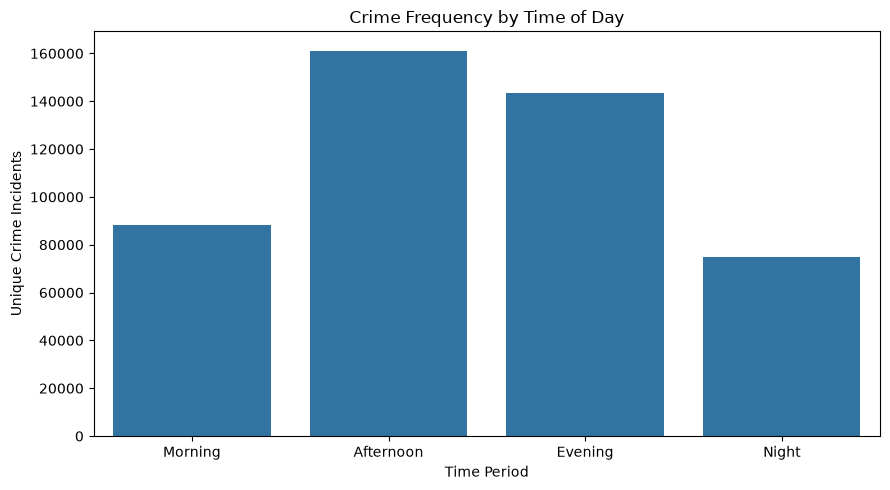

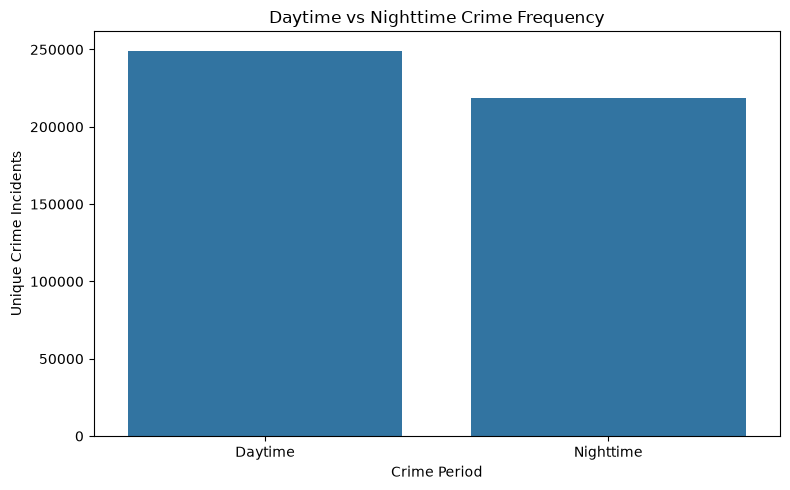

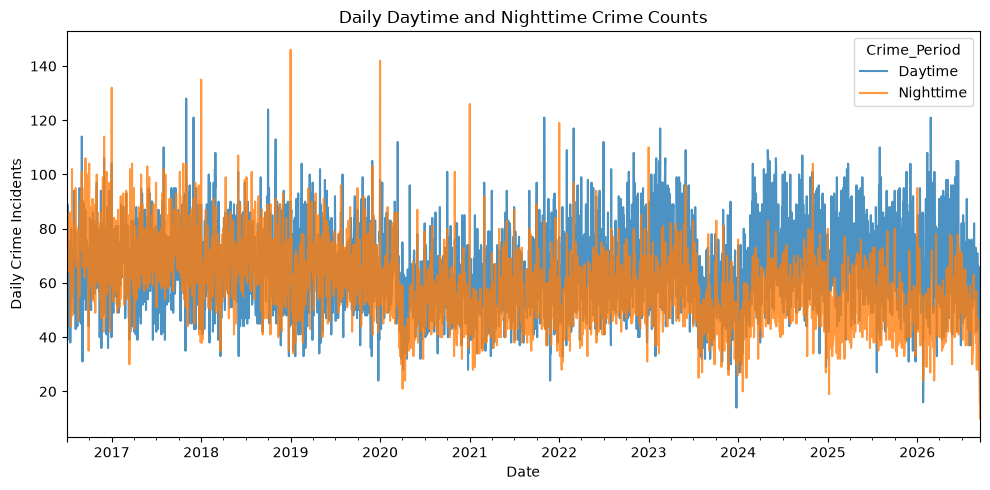


ANALYSIS COMPLETED SUCCESSFULLY
Statistical tables and graphs have been saved.


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chisquare, wilcoxon

# ----------------------------------------------------------
# MODULE 1: LOAD DATASET
# ----------------------------------------------------------

file_path = "dataset_coursework1-1.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Original dataset shape:", df.shape)

# ----------------------------------------------------------
# MODULE 2: DATA PREPROCESSING
# ----------------------------------------------------------

df["Start_Date_Time"] = pd.to_datetime(
    df["Start_Date_Time"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

# Remove records without incident ID or occurrence time
df = df.dropna(
    subset=["Incident ID", "Start_Date_Time"]
).copy()

# Count each incident once.
# Multiple offence rows may belong to one incident.
df = df.drop_duplicates(
    subset=["Incident ID"]
).copy()

print("Unique incidents:", len(df))

# ----------------------------------------------------------
# MODULE 3: TIME CLASSIFICATION
# ----------------------------------------------------------

df["Hour"] = df["Start_Date_Time"].dt.hour

def classify_time(hour):

    if 6 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 18:
        return "Afternoon"

    elif 18 <= hour < 24:
        return "Evening"

    else:
        return "Night"

df["Time_Period"] = df["Hour"].apply(classify_time)

df["Crime_Period"] = df["Time_Period"].map({

    "Morning": "Daytime",
    "Afternoon": "Daytime",
    "Evening": "Nighttime",
    "Night": "Nighttime"

})

df["Date"] = df["Start_Date_Time"].dt.normalize()

# ----------------------------------------------------------
# MODULE 4: DESCRIPTIVE STATISTICS
# ----------------------------------------------------------

time_order = [
    "Morning", "Afternoon", "Evening", "Night"
]

period_order = ["Daytime", "Nighttime"]

time_counts = (
    df["Time_Period"]
    .value_counts()
    .reindex(time_order, fill_value=0)
)

period_counts = (
    df["Crime_Period"]
    .value_counts()
    .reindex(period_order, fill_value=0)
)

percentage = (
    period_counts / period_counts.sum()
) * 100

summary = pd.DataFrame({

    "Crime_Count": period_counts,
    "Percentage": percentage

})

print("\nDAYTIME AND NIGHTTIME STATISTICS")
print(summary)

# ----------------------------------------------------------
# MODULE 5: DAILY STATISTICS
# ----------------------------------------------------------

daily = df.pivot_table(

    index="Date",
    columns="Crime_Period",
    values="Incident ID",
    aggfunc="count",
    fill_value=0

)

# Include dates with zero recorded incidents
all_dates = pd.date_range(
    df["Date"].min(),
    df["Date"].max(),
    freq="D"
)

daily = daily.reindex(
    index=all_dates,
    columns=period_order,
    fill_value=0
)

daily.index.name = "Date"

daily_stats = daily.agg(["mean", "std", "median", "min", "max"])

print("\nDAILY CRIME STATISTICS")
print(daily_stats)

# ----------------------------------------------------------
# MODULE 6: CHI-SQUARE GOODNESS-OF-FIT TEST
# ----------------------------------------------------------

observed = period_counts.values

expected = [
    period_counts.sum() / 2,
    period_counts.sum() / 2
]

chi_stat, chi_p = chisquare(

    f_obs=observed,
    f_exp=expected

)

print("\nCHI-SQUARE TEST")
print("Chi-square statistic:", chi_stat)
print("P-value:", chi_p)

# ----------------------------------------------------------
# MODULE 7: PAIRED WILCOXON TEST
# ----------------------------------------------------------

day_values = daily["Daytime"]
night_values = daily["Nighttime"]

if (day_values != night_values).any():

    wil_stat, wil_p = wilcoxon(
        day_values,
        night_values,
        alternative="two-sided"
    )

else:
    wil_stat, wil_p = np.nan, np.nan

print("\nWILCOXON SIGNED-RANK TEST")
print("Test statistic:", wil_stat)
print("P-value:", wil_p)

# ----------------------------------------------------------
# MODULE 8: EFFECT SIZE
# ----------------------------------------------------------

differences = day_values - night_values

if differences.std(ddof=1) > 0:

    cohens_dz = (
        differences.mean() /
        differences.std(ddof=1)
    )

else:
    cohens_dz = np.nan

print("\nPAIRED EFFECT SIZE")
print("Cohen's dz:", cohens_dz)

# ----------------------------------------------------------
# MODULE 9: HYPOTHESIS DECISION
# ----------------------------------------------------------

alpha = 0.05

print("\nRESEARCH HYPOTHESIS RESULTS")

if wil_p < alpha:

    print("Reject H0")
    print("Evidence of a significant daily difference.")

else:

    print("Fail to reject H0")
    print("Insufficient evidence of a daily difference.")

# ----------------------------------------------------------
# MODULE 10: VISUALISATION
# ----------------------------------------------------------

# Chart 1: Four time periods

plt.figure(figsize=(9, 5))

sns.barplot(
    x=time_counts.index,
    y=time_counts.values
)

plt.title("Crime Frequency by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Unique Crime Incidents")

plt.tight_layout()
plt.savefig("crime_four_time_periods.png", dpi=300)
plt.show()

# Chart 2: Daytime vs Nighttime

plt.figure(figsize=(8, 5))

sns.barplot(
    x=period_counts.index,
    y=period_counts.values
)

plt.title("Daytime vs Nighttime Crime Frequency")
plt.xlabel("Crime Period")
plt.ylabel("Unique Crime Incidents")

plt.tight_layout()
plt.savefig("daytime_nighttime_comparison.png", dpi=300)
plt.show()

# Chart 3: Daily crime comparison

plt.figure(figsize=(10, 5))

daily.plot(
    y=period_order,
    ax=plt.gca(),
    alpha=0.8
)

plt.title("Daily Daytime and Nighttime Crime Counts")
plt.xlabel("Date")
plt.ylabel("Daily Crime Incidents")

plt.tight_layout()
plt.savefig("daily_crime_comparison.png", dpi=300)
plt.show()

# ----------------------------------------------------------
# MODULE 11: EXPORT RESULTS
# ----------------------------------------------------------

summary.to_csv("crime_statistical_summary.csv")

daily.to_csv("daily_crime_statistics.csv")

print("\nANALYSIS COMPLETED SUCCESSFULLY")
print("Statistical tables and graphs have been saved.")


Interpretation:

The statistical results indicate that daytime experienced a higher number of recorded crimes than nighttime. Daytime accounts for 53.31% of all unique recorded incidents, compared with 46.69% during nighttime.

Conclusion
This research investigated the variation in recorded crime incidents between daytime (morning and afternoon) and nighttime (evening and night) in Montgomery County, Maryland. The study utilised historical crime records and statistical analysis techniques to examine crime frequency patterns according to the time of occurrence.The analysis identified 467,601 unique crime incidents in the dataset. The findings revealed that 249,273 incidents (53.31%) occurred during daytime, while 218,328 incidents (46.69%) occurred during nighttime.
The descriptive statistical analysis demonstrated that the average daily crime frequency was higher during daytime, with approximately 66.87 recorded incidents per day, compared with 58.56 incidents during nighttime.
Furthermore, the Wilcoxon signed-rank test identified a statistically significant difference between daily daytime and nighttime crime frequencies (p < 0.001). Consequently, the null hypothesis was rejected, and the alternative hypothesis was supported.
Based on these findings, the research establishes that the number of recorded crime incidents varies significantly between daytime and nighttime in Montgomery County, Maryland. In particular, the dataset indicates a higher frequency of recorded crime incidents during daytime.


RQ8:Are there significant differences between violent crime and property crime distributions

C:\Users\acer\AppData\Local\Temp\ipykernel_3552\2759561258.py:7: DtypeWarning: Columns (1: Offence Code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("dataset_coursework1-1.csv")



CRIME CATEGORY FREQUENCIES
Crime_Category
Property Crime    246236
Violent Crime      53385
Name: count, dtype: int64

CRIME CATEGORY PERCENTAGES
Crime_Category
Property Crime    82.182491
Violent Crime     17.817509
Name: proportion, dtype: float64

CONTINGENCY TABLE
Crime_Category        Property Crime  Violent Crime
Police District Name                               
BETHESDA                       42168           5647
GERMANTOWN                     30733           8381
MONTGOMERY VILLAGE             36971          10940
ROCKVILLE                      30451           6258
SILVER SPRING                  53493          10923
TAKOMA PARK                     8830           1124
WHEATON                        42816           9923

CHI-SQUARE TEST RESULTS
Chi-square statistic: 2723.3460831904986
Degrees of freedom: 6
P-value: 0.0
Cramer's V: 0.09549141774646475

Reject the null hypothesis.
Crime category and police district are associated.

VIOLENT CRIME PERCENTAGE BY DISTRICT
Police Dist

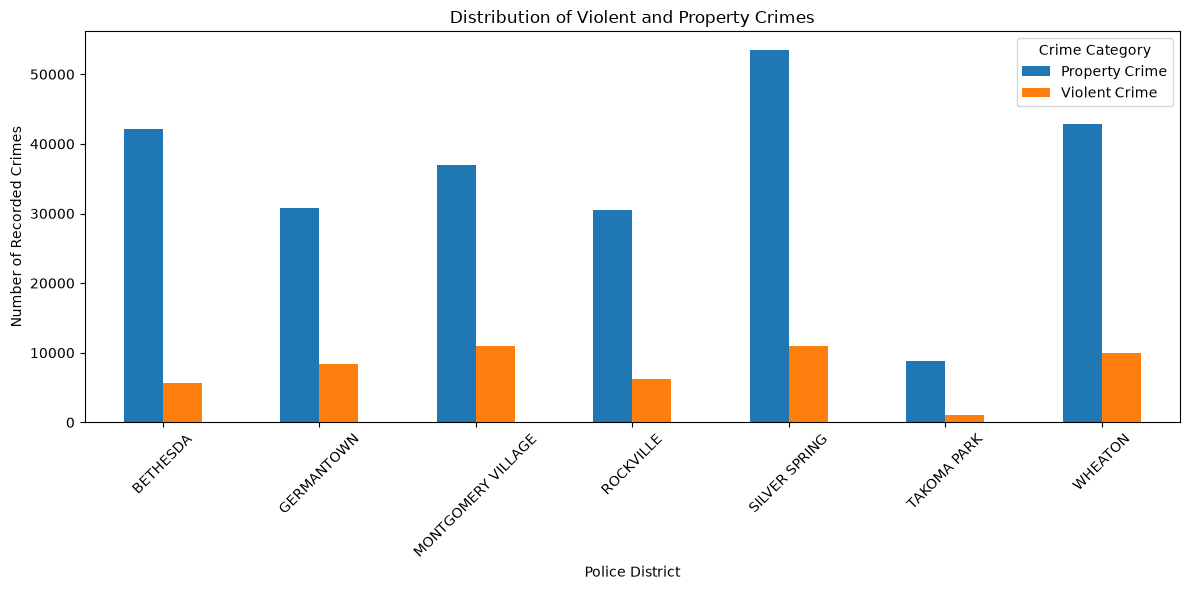

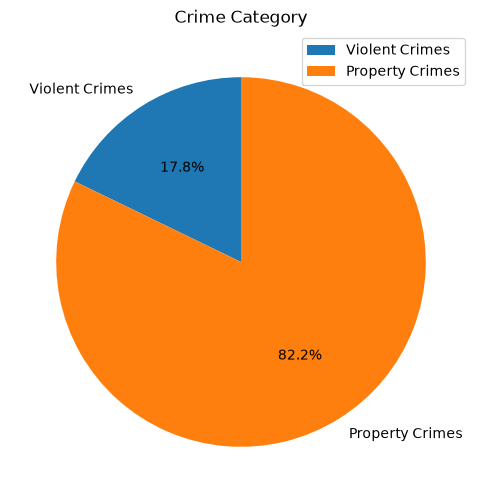

In [34]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Load dataset
df = pd.read_csv("dataset_coursework1-1.csv")

# Select violent and property crimes
data = df[
    df["Crime Name1"].isin([
        "Crime Against Person",
        "Crime Against Property"
    ])
].copy()

# Rename categories
data["Crime_Category"] = data["Crime Name1"].map({
    "Crime Against Person": "Violent Crime",
    "Crime Against Property": "Property Crime"
})

# Descriptive statistics
print("\nCRIME CATEGORY FREQUENCIES")
print(data["Crime_Category"].value_counts())

print("\nCRIME CATEGORY PERCENTAGES")
print(data["Crime_Category"].value_counts(normalize=True) * 100)

# Remove missing and OTHER districts
data = data[
    data["Police District Name"].notna() &
    (data["Police District Name"] != "OTHER")
]

# Create contingency table
table = pd.crosstab(
    data["Police District Name"],
    data["Crime_Category"]
)

print("\nCONTINGENCY TABLE")
print(table)

# Chi-square test
chi2, p, dof, expected = chi2_contingency(table)

# Cramer's V
n = table.to_numpy().sum()
cramers_v = np.sqrt(
    chi2 / (n * min(table.shape[0]-1, table.shape[1]-1))
)

print("\nCHI-SQUARE TEST RESULTS")
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p)
print("Cramer's V:", cramers_v)

# Hypothesis decision
alpha = 0.05

if p < alpha:
    print("\nReject the null hypothesis.")
    print("Crime category and police district are associated.")
else:
    print("\nFail to reject the null hypothesis.")

# Calculate violent crime percentage by district
violent_percentage = (
    table["Violent Crime"] / table.sum(axis=1) * 100
)

print("\nVIOLENT CRIME PERCENTAGE BY DISTRICT")
print(violent_percentage.round(2))

# Visualisation
table.plot(kind="bar", figsize=(12, 6))

plt.title("Distribution of Violent and Property Crimes")
plt.xlabel("Police District")
plt.ylabel("Number of Recorded Crimes")
plt.xticks(rotation=45)
plt.legend(title="Crime Category")
plt.tight_layout()
plt.show()

df = pd.DataFrame({
    "Category": ["Violent Crimes","Property Crimes"],
    "Crimes": [53385,246236,],
})

df.plot(
    kind="pie",
    y="Crimes",
    labels=df["Category"],
    autopct="%1.1f%%",
    figsize=(6, 6),
    startangle=90,
)
plt.ylabel("")
plt.title("Crime Category")
plt.show()